# 03 · One-stage anchor-free detector: YOLOv8

**Accelerator: GPU T4 x2** Inputs: competition data, `vd-utils`, output of notebook `00`.

**Protocol shared by all detectors**
- train: folds ≠ 0, every 10th frame, masked + resized frames from notebook 00
- val: fold 0, every 10th frame, **original** images
- metrics: `vd_utils.coco_evaluate` (COCO mAP, ignore regions as `iscrowd=1`, up to 500 detections per image, size buckets in original pixels)
- speed: batch 1, FP32, one T4, pre- and post-processing included

**Runs** (each changes one thing relative to the previous one)

| run           | change                                 | motivation from EDA                                      |
|---------------|----------------------------------------|----------------------------------------------------------|
| `v8s_640`     | baseline, default Ultralytics settings | reference                                                |
| `v8s_1024`    | input 640 → 1024                       | at 640 a large share of objects shrinks below 8 px       |
| `v8s_p2_1024` | + P2 head (stride 4)                   | objects of 10–20 px get only 1–2 grid points at stride 8 |

Runs were trained in separate notebook versions (`RUNS_TO_TRAIN`); finished runs are loaded from earlier outputs attached as input.
This version trains `v8s_640`; `v8s_1024` and `v8s_p2_1024` come from the previous version.

In [1]:
# --- Install Ultralytics and import shared utilities ---------------------------
import os, sys, glob, gc, json, time, zipfile, subprocess, traceback
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
try:
    import pycocotools
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import ultralytics
from ultralytics import YOLO, settings
settings.update({"wandb": False})
os.environ["WANDB_MODE"] = "disabled"

def find_utils():
    if os.path.exists("vd_utils.py"):
        return "."
    for depth in range(1, 6):
        hits = glob.glob(os.path.join("/kaggle/input", *["*"] * depth, "vd_utils.py"))
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError("Add the vd-utils dataset as notebook input")

sys.path.insert(0, find_utils())
import vd_utils as U

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| GPUs", torch.cuda.device_count())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.208 | torch 2.11.0+cu130 | GPUs 2


In [2]:
# --- Configuration --------------------------------------------------------------
SEED = 42
VAL_FOLD, STEP = 0, 10          # same split and subsampling for every detector
EPOCHS, BATCH, WORKERS = 30, 16, 4
DEVICE = [0, 1] if torch.cuda.device_count() > 1 else 0   # DDP on both T4s
CONF, NMS_IOU = 0.001, 0.7      # low threshold: mAP needs the whole precision-recall curve
WORK = "/kaggle/working"

RUNS = {
    "v8s_640":     dict(model="yolov8s.pt", imgsz=640),
    "v8s_1024":    dict(model="yolov8s.pt", imgsz=1024),
    "v8s_p2_1024": dict(model="yolov8s-p2.yaml", pretrained="yolov8s.pt", imgsz=1024, batch=8),
}
RUNS_TO_TRAIN = ["v8s_640"] # edit per notebook version
U.seed_everything(SEED)
os.makedirs(f"{WORK}/results", exist_ok=True)

## Data

Ultralytics reads image lists; labels are found by replacing `/images/` with `/labels/` in each path.
Training images come from notebook 00 (ignore regions masked); validation images are the original frames with the competition's YOLO labels.
The COCO ground truth for our evaluator is built from the same validation frames.

In [3]:
# --- Image lists, data.yaml and COCO ground truth for the holdout fold ------------
frames, anns = U.load_prep()
train_folds = [f for f in sorted(frames.fold.unique()) if f != VAL_FOLD]
tr = U.select_frames(frames, folds=train_folds, step=STEP)
va = U.select_frames(frames, folds=VAL_FOLD, step=STEP)
val_paths = U.orig_image_paths(va)
data_yaml = U.write_yolo_data(U.train_image_paths(tr), val_paths, out_dir=f"{WORK}/yolo_data")
gt_json, key2id = U.make_coco_gt(va, anns, f"{WORK}/gt_val.json")
val_ids = [key2id[k] for k in va.key]
print(f"train {len(tr)} frames / {tr["clip"].nunique()} clips | val {len(va)} frames / {va["clip"].nunique()} clips")

train 2161 frames / 50 clips | val 573 frames / 13 clips


In [4]:
# --- Helpers: locate a finished run, predict, evaluate ---------------------------
def run_dir(name):
    # a run trained in this session, or one from an earlier version attached as input
    if os.path.exists(f"{WORK}/runs/{name}/weights/best.pt"):
        return f"{WORK}/runs/{name}"
    for top in sorted(os.listdir("/kaggle/input")) if os.path.isdir("/kaggle/input") else []:
        if top == "competitions" or U.COMP_SLUG in top:
            continue
        for dirpath, dirnames, filenames in os.walk(os.path.join("/kaggle/input", top)):
            dirnames[:] = [d for d in dirnames if d not in ("train_masked", "images", "labels")]
            if dirpath.endswith(os.path.join("runs", name, "weights")) and "best.pt" in filenames:
                return os.path.dirname(dirpath)
    return None

def predict(model, source, imgsz, **kw):
    return model.predict(source, imgsz=imgsz, conf=CONF, iou=NMS_IOU, max_det=U.MAX_DET,
                         device=0, verbose=False, **kw)

def boxes_of(r):
    b = r.boxes
    return b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int)

def evaluate_run(name):
    gc.collect(); torch.cuda.empty_cache()
    d, imgsz = run_dir(name), RUNS[name]["imgsz"]
    model = YOLO(f"{d}/weights/best.pt")
    dets = []
    for img_id, p in zip(val_ids, val_paths):
        r = predict(model, p, imgsz)[0]          # one frame at a time: GPU memory does not grow with batch size
        dets += U.to_coco_dets(img_id, *boxes_of(r))
    m = U.coco_evaluate(gt_json, dets)
    m["FPS"] = round(U.measure_fps(lambda p: predict(model, p, imgsz), val_paths[:110]), 1)
    info_file = f"{d}/train_info.json"
    m["train_h"] = json.load(open(info_file))["train_hours"] if os.path.exists(info_file) else float("nan")
    return m

## Training

Pretrained COCO weights, default Ultralytics recipe: SGD/AdamW auto-selected, linear LR decay, warmup 3 epochs,
augmentation = mosaic (off for the last 5 epochs), random scale ±50 %, translation, horizontal flip, HSV jitter.
Images are normalised to [0, 1]. Loss: BCE for classes, CIoU + DFL for boxes; positives are chosen by the Task-Aligned Assigner.

In [5]:
# --- Train the selected runs --------------------------------------------------------
for name in RUNS_TO_TRAIN:
    cfg = RUNS[name]
    t0 = time.time()
    YOLO(cfg["model"]).train(
        data=data_yaml, imgsz=cfg["imgsz"], pretrained=cfg.get("pretrained", True),
        epochs=EPOCHS, batch=cfg.get("batch", BATCH), device=DEVICE, workers=WORKERS, seed=SEED,
        max_det=U.MAX_DET, close_mosaic=5, cache="ram",
        project=f"{WORK}/runs", name=name, exist_ok=True, plots=True, verbose=False)
    with open(f"{WORK}/runs/{name}/train_info.json", "w") as f:
        json.dump({"train_hours": round((time.time() - t0) / 3600, 2), "epochs": EPOCHS, **cfg}, f)
    print(f"{name}: {(time.time() - t0) / 60:.0f} min")

30 epochs completed in 0.165 hours.
Optimizer stripped from /kaggle/working/runs/v8s_640/weights/last.pt, 22.5MB
Optimizer stripped from /kaggle/working/runs/v8s_640/weights/best.pt, 22.5MB

Validating /kaggle/working/runs/v8s_640/weights/best.pt...
Model summary (fused): 72 layers, 11,128,680 parameters, 0 gradients, 28.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 5.6it/s 3.2s
                   all        573      21981      0.468      0.327      0.327      0.169
Speed: 0.1ms preprocess, 1.7ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/runs/v8s_640
v8s_640: 14 min


## Validation results

All runs are evaluated with the same code on the same 573 holdout frames (13 clips).
`AP_small/medium/large` use COCO size buckets in original pixels (< 32², < 96², larger).

In [6]:
# --- Evaluate every finished run with the shared COCO evaluator ---------------------
results = {}
for name in RUNS:
    if run_dir(name) is None:
        print(f"{name}: not trained yet")
        continue
    try:
        results[name] = evaluate_run(name)
    except Exception:
        traceback.print_exc()    # keep the notebook alive: Kaggle drops the output (weights) of failed versions
        continue
    with open(f"{WORK}/results/{name}.json", "w") as f:
        json.dump(results[name], f)

if results:
    res = pd.DataFrame(results).T
    main_cols = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500", "FPS", "train_h"]
    display(res[main_cols])
    display(res[[f"AP_{c}" for c in U.CLASSES]])
else:
    print("No evaluated run: set RUNS_TO_TRAIN or attach the output of a version that finished successfully.")

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,FPS,train_h
v8s_640,0.1683,0.3240,0.1582,0.0633,0.1403,0.3637,0.2749,52.7,0.23
v8s_1024,0.2238,0.4207,0.2103,0.0918,0.2010,0.4098,0.3408,34.0,0.41
v8s_p2_1024,0.2151,0.4176,0.1927,0.0836,0.1843,0.4132,0.3470,25.2,0.63


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
v8s_640,0.1593,0.0112,0.4440,0.0919,0.1126,0.1401,0.2933,0.0998
v8s_1024,0.2283,0.0544,0.4759,0.1796,0.1708,0.2047,0.3579,0.1277
v8s_p2_1024,0.2130,0.0568,0.4611,0.1536,0.1364,0.1946,0.3856,0.1291


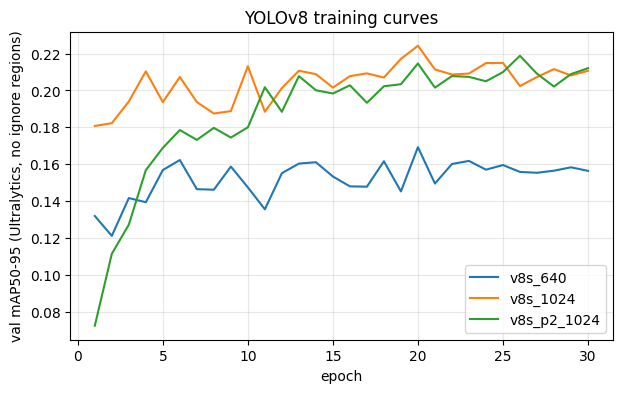

In [7]:
# --- Validation mAP per epoch (Ultralytics' own metric, used for the RT-DETR comparison) ----
plt.figure(figsize=(7, 4))
for name in RUNS:
    d = run_dir(name)
    if d and os.path.exists(f"{d}/results.csv"):
        h = pd.read_csv(f"{d}/results.csv")
        h.columns = h.columns.str.strip()
        h.to_csv(f"{WORK}/results/{name}_curve.csv", index=False)
        plt.plot(h["epoch"], h["metrics/mAP50-95(B)"], label=name)
plt.xlabel("epoch"); plt.ylabel("val mAP50-95 (Ultralytics, no ignore regions)")
plt.legend(); plt.grid(alpha=.3); plt.title("YOLOv8 training curves")
plt.savefig(f"{WORK}/results/yolo_curves.png", dpi=120, bbox_inches="tight"); plt.show()

## How locations are assigned without anchors

YOLOv8 predicts one box per **grid point** (feature-map cell centre) at strides 8, 16, 32 (plus 4 with the P2 head).
There are no prior box shapes: each point regresses the distances to the four box edges (as discrete distributions, DFL).

During training the **Task-Aligned Assigner** (TOOD) picks positives for each GT box:
1. candidate points are those whose centre lies **inside** the GT box;
2. each candidate gets an alignment score $t = s^{\alpha} \cdot u^{\beta}$ ($s$ = predicted class score, $u$ = IoU of its predicted box with the GT, $\alpha=0.5$, $\beta=6$);
3. the top-10 candidates by $t$ become positives; a point claimed by several GTs keeps the one with the highest IoU.

**Consequences for this dataset.** A 12 px object contains about $(12/8)^2 \approx 2$ grid points at stride 8, so it competes with its neighbours for very few candidates, and in dense rows of cars adjacent objects share the same points.
Increasing the input size enlarges objects in feature-map units; the P2 head (stride 4) quadruples the number of candidate points per object.
Both changes target `AP_small`, which is why they were chosen as the two tuned parameters.

*Search range and selection: input ∈ {640, 1024}, P2 head ∈ {off, on}; selected = best holdout mAP (table above).*

## Test submission

The run with the best holdout mAP predicts all test frames at its training resolution.
Boxes are already in original pixels; at most 500 per image, sorted by score.

In [8]:
# --- Predict the test set with the best run and write the submission ----------------
def make_submission(name):
    gc.collect(); torch.cuda.empty_cache()
    model, imgsz = YOLO(f"{run_dir(name)}/weights/best.pt"), RUNS[name]["imgsz"]
    test = pd.read_csv(os.path.join(U.comp_root(), "test_images.csv"))
    pred = {}
    for i, (image_id, rel) in enumerate(zip(test.image_id, test.file_name)):
        r = predict(model, os.path.join(U.comp_root(), rel), imgsz)[0]      # one frame at a time
        pred[image_id] = U.prediction_string(*boxes_of(r))
        if i % 1000 == 0:
            print(f"{i}/{len(test)}")
    sub_path = f"{WORK}/submission_{name}.csv"
    sub = U.write_submission(pred, sub_path)
    with zipfile.ZipFile(sub_path[:-4] + ".zip", "w", zipfile.ZIP_DEFLATED) as z:
        z.write(sub_path, os.path.basename(sub_path))
    print(f"{name}: {len(sub)} rows, {(sub.PredictionString != '').mean():.1%} non-empty, "
          f"csv {os.path.getsize(sub_path) / 1e6:.0f} MB, zip {os.path.getsize(sub_path[:-4] + '.zip') / 1e6:.0f} MB")

if results:
    try:
        make_submission(max(results, key=lambda n: results[n]["mAP"]))
    except Exception:
        traceback.print_exc()
else:
    print("No evaluated run: submission skipped.")

0/3811
1000/3811
2000/3811
3000/3811
v8s_1024: 3811 rows, 100.0% non-empty, csv 44 MB, zip 16 MB


## Conclusions

| run | change | mAP | AP50 | AP_small | AP_medium | AP_large | AR500 | FPS | train h | public LB |
|---|---|---|---|---|---|---|---|---|---|---|
| `v8s_640` | baseline | 0.168 | 0.324 | 0.063 | 0.140 | 0.364 | 0.275 | 53 | 0.23 | 0.2085 * |
| `v8s_1024` | input 1024 | **0.224** | **0.421** | **0.092** | **0.201** | 0.410 | 0.341 | 34 | 0.41 | **0.2271** |
| `v8s_p2_1024` | + P2 head | 0.215 | 0.418 | 0.084 | 0.184 | **0.413** | **0.347** | 25 | 0.63 | – |

\* submitted from the first training of `v8s_640`; the run in this table is a retrain with the same settings.

- **Search range and selection:** input size ∈ {640, 1024}, P2 head ∈ {off, on}; selected `v8s_1024` (best holdout mAP).
- **Input size is the main lever.** 640 → 1024 adds +0.056 mAP and +0.029 `AP_small` (+45 % relative) and improves every class, most of all the small ones (`van` 0.09 → 0.18, `bicycle` 0.01 → 0.05). At 640 a median object shrinks to 15 px, i.e. about two stride-8 grid points, which is too few for the task-aligned assigner to pick good positives. Cost: 53 → 34 FPS.
- **The P2 head did not help within the budget.** Recall rises slightly (AR500 0.341 → 0.347) but localisation gets worse (AP75 0.210 → 0.193) and `AP_small` drops. The P2 layers are built from yaml without pretrained weights, so 30 epochs on 2 161 frames are not enough to train them; with batch 8 (memory) the run also took 50 % longer and runs 26 % slower.
- **Holdout vs leaderboard.** Holdout mAP 0.224 vs public LB 0.227 for `v8s_1024`: our evaluator (ignore regions as crowd, ≤ 500 detections) tracks the leaderboard metric (COCO mAP@[.5:.95]).

**Comparison with the tuned anchor-based detectors** (same holdout; torchvision models run at 1344 px, YOLO at 1024 px)

| model | mAP | AP_small | AP_medium | AP_large | FPS |
|---|---|---|---|---|---|
| YOLOv8s 640 (initial, anchor-free) | 0.168 | 0.063 | 0.140 | 0.364 | 53 |
| YOLOv8s 1024 (tuned, anchor-free) | 0.224 | 0.092 | 0.201 | 0.410 | 34 |
| RetinaNet (`retina_base`, anchor-based one-stage) | 0.226 | 0.088 | 0.201 | **0.457** | 5 |
| Faster R-CNN (`frcnn_props`, two-stage) | **0.240** | **0.100** | **0.212** | 0.428 | 5 |

The tuned anchor-free model matches RetinaNet on small and medium objects with a smaller input (1024 vs 1344 px) and is ~7× faster; the two-stage detector keeps a lead of +0.008 `AP_small` and +0.016 mAP, which comes from its second refinement step and from seeing 1.3× larger images. Large objects favour the anchor-based models, whose largest anchors (up to 812 px) cover buses and trucks better than YOLO's stride-32 grid trained on few large examples. Because YOLO is 7× faster, it is the base of the final pipeline, where the resolution, data and model size can be pushed further within the budget.